[![../img/pythonista.png](../img/pythonista.png)](https://www.pythonista.io)

# Calidad de datos y valores faltantes.

**py401 · EDA Práctico** · Pythonista® · Instructor: José Luis Chiquete
**Martes 20 de octubre de 2026 · 6:30 a 8:30 pm (CDMX)** · Módulo I: *Datos y su calidad*

> 🔑 **Versión con soluciones** — solo para el instructor / revisión posterior.

## 🎯 Objetivo de la sesión
**Auditar la calidad de un dataset y elegir de forma justificada cómo tratar los faltantes.**

Al terminar podrás:
1. Aplicar una lista de verificación de calidad a cualquier dataset.
2. Detectar y resolver duplicados exactos y por llave.
3. Corregir inconsistencias de texto, categorías mal escritas, rangos imposibles y unidades.
4. Distinguir los mecanismos de faltantes (MCAR, MAR, MNAR) y perfilarlos.
5. Comparar eliminación, imputación simple, imputación por grupo e indicador de faltante, y medir su efecto en las distribuciones.

## 🗺️ Agenda (120 min)
| Min | Bloque |
|---|---|
| 10 | Repaso y lista de verificación de calidad |
| 20 | 1. Duplicados: exactos y por llave |
| 25 | 2. Inconsistencias: texto, categorías, rangos imposibles, unidades |
| 15 | 3. Mecanismos de faltantes y cómo perfilarlos |
| 30 | 4. Tratamiento de faltantes y su efecto en las distribuciones |
| 20 | 5. Ejercicio (`titanic` + `penguins`) y cierre |

🟢 = ejercicio básico · 🔴 = reto opcional

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ubica la carpeta data/ tanto desde la raíz del repositorio como desde soluciones/
DATA = next(os.path.join(p, "data") for p in (os.curdir, os.pardir)
            if os.path.isfile(os.path.join(p, "data", "penguins.csv")))
pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")
rng = np.random.default_rng(401)

pinguinos = pd.read_csv(os.path.join(DATA, "penguins.csv"))
titanic = pd.read_csv(os.path.join(DATA, "titanic.csv"))
print("penguins:", pinguinos.shape, "| titanic:", titanic.shape)

penguins: (344, 7) | titanic: (891, 15)


---
## 0. Repaso y lista de verificación de calidad (10 min)

Ayer construimos el diccionario de datos y vimos que `penguins` tiene faltantes. Hoy los auditamos con orden. **Lista de verificación** que usaremos en todo el curso (y en el proyecto):

| # | Pregunta | Herramientas |
|---|---|---|
| 1 | ¿Forma y tipos correctos? | `shape`, `info`, `dtypes` |
| 2 | ¿Hay una llave? ¿Es única? | `duplicated(subset=...)`, `nunique` |
| 3 | ¿Filas duplicadas exactas? | `duplicated()`, `drop_duplicates()` |
| 4 | ¿Categorías consistentes? | `value_counts(dropna=False)`, `str.strip/lower` |
| 5 | ¿Valores en rangos posibles? ¿Unidades homogéneas? | `describe`, `between`, reglas de dominio |
| 6 | ¿Cuántos faltantes, dónde y por qué? | `isna().sum()`, patrones por grupo |
| 7 | ¿Qué decisión tomo y cómo afecta? | comparar antes/después |

> 💡 **Regla de oro:** nunca limpies "en silencio". Cada decisión se **documenta** y se **cuantifica** (cuántas filas afecta y cómo cambia el resultado).

### 🟢 Ejercicio 1 · Perfil rápido reutilizable
Escribe una función `perfil_rapido(df)` que devuelva un DataFrame con una fila por columna y las columnas `dtype`, `n_faltantes`, `pct_faltantes` (0–100, con 1 decimal), `n_unicos` y `ejemplo` (el primer valor no nulo). Pruébala con `pinguinos` y con `titanic`. Te servirá en el resto del curso.

In [2]:
def perfil_rapido(df):
    # Una fila por columna con lo esencial de calidad
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_faltantes": df.isna().sum(),
        "pct_faltantes": (df.isna().mean() * 100).round(1),
        "n_unicos": df.nunique(dropna=True),
        "ejemplo": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df.columns],
    })

display(perfil_rapido(pinguinos))
perfil_rapido(titanic).sort_values("pct_faltantes", ascending=False)

,dtype,n_faltantes,pct_faltantes,n_unicos,ejemplo
species,object,0,0.0,3,Adelie
island,object,0,0.0,3,Torgersen
bill_length_mm,float64,2,0.6,164,39.1
bill_depth_mm,float64,2,0.6,80,18.7
flipper_length_mm,float64,2,0.6,55,181.0
body_mass_g,float64,2,0.6,94,3750.0
sex,object,11,3.2,2,MALE


,dtype,n_faltantes,pct_faltantes,n_unicos,ejemplo
deck,object,688,77.2,7,C
age,float64,177,19.9,88,22.0
embarked,object,2,0.2,3,S
embark_town,object,2,0.2,3,Southampton
sex,object,0,0.0,2,male
pclass,int64,0,0.0,3,3
survived,int64,0,0.0,2,0
fare,float64,0,0.0,248,7.25
parch,int64,0,0.0,7,0
sibsp,int64,0,0.0,7,1


---
## 1. Duplicados: exactos y por llave (20 min)

- **Duplicado exacto:** toda la fila se repite. Suele deberse a cargas repetidas o *joins* mal hechos.
- **Duplicado por llave:** la llave (p. ej., `id`) se repite aunque otras columnas difieran. Es más peligroso: hay que **decidir qué registro es el bueno**.

`df.duplicated()` marca con `True` cada fila que **ya apareció antes** (`keep="first"`); con `keep=False` marca todas las copias.

In [3]:
# Un pequeño registro de inscripciones al curso
inscripciones = pd.DataFrame({
    "id_alumno": [101, 102, 103, 102, 104, 105, 105],
    "nombre":    ["Ana", "Luis", "Marta", "Luis", "Iván", "Sofía", "Sofía"],
    "correo":    ["ana@x.mx", "luis@x.mx", "marta@x.mx", "luis@x.mx", "ivan@x.mx", "sofia@x.mx", "sofia.r@x.mx"],
    "fecha":     ["2026-10-01", "2026-10-02", "2026-10-02", "2026-10-02", "2026-10-05", "2026-10-06", "2026-10-09"],
})
print("duplicados exactos:", inscripciones.duplicated().sum())
print("duplicados por llave:", inscripciones.duplicated(subset=["id_alumno"]).sum())
inscripciones[inscripciones.duplicated(subset=["id_alumno"], keep=False)]

duplicados exactos: 1
duplicados por llave: 2


,id_alumno,nombre,correo,fecha
1,102,Luis,luis@x.mx,2026-10-02
3,102,Luis,luis@x.mx,2026-10-02
5,105,Sofía,sofia@x.mx,2026-10-06
6,105,Sofía,sofia.r@x.mx,2026-10-09


In [4]:
# Política explícita: para cada alumno conservamos el registro MÁS RECIENTE (correo actualizado)
inscripciones_limpio = (
    inscripciones
    .sort_values("fecha")
    .drop_duplicates(subset=["id_alumno"], keep="last")
    .sort_values("id_alumno")
)
inscripciones_limpio

,id_alumno,nombre,correo,fecha
0,101,Ana,ana@x.mx,2026-10-01
3,102,Luis,luis@x.mx,2026-10-02
2,103,Marta,marta@x.mx,2026-10-02
4,104,Iván,ivan@x.mx,2026-10-05
6,105,Sofía,sofia.r@x.mx,2026-10-09


### ⚠️ ¿Todo duplicado exacto es un error? El caso `titanic`

In [5]:
n_dup = titanic.duplicated().sum()
print(f"titanic tiene {n_dup} filas idénticas a otra anterior ({n_dup / len(titanic):.1%})")
titanic[titanic.duplicated(keep=False)].sort_values(["class", "sex", "age"]).head(6)

titanic tiene 107 filas idénticas a otra anterior (12.0%)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
369,1,1,female,24.0,0,0,69.3000,C,First,woman,False,B,Cherbourg,yes,True
641,1,1,female,24.0,0,0,69.3000,C,First,woman,False,B,Cherbourg,yes,True
64,0,1,male,NaN,0,0,27.7208,C,First,man,True,NaN,Cherbourg,no,True
295,0,1,male,NaN,0,0,27.7208,C,First,man,True,NaN,Cherbourg,no,True
443,1,2,female,28.0,0,0,13.0000,S,Second,woman,False,NaN,Southampton,yes,True
635,1,2,female,28.0,0,0,13.0000,S,Second,woman,False,NaN,Southampton,yes,True


`titanic` **no tiene llave** (no hay nombre ni número de boleto). Dos hombres de tercera clase, sin edad registrada, que embarcaron en Southampton y pagaron la misma tarifa son **personas distintas** con los mismos atributos. Borrar esas filas eliminaría pasajeros reales y sesgaría el análisis.

> Sin una llave, un duplicado exacto es solo **sospechoso**, no necesariamente un error. Decide con conocimiento del origen de los datos.

### Un dataset "sucio" para practicar
La función de abajo toma `penguins` y le introduce, con semilla fija, problemas típicos del mundo real: una llave `id_muestra`, duplicados, texto inconsistente, unidades mezcladas y códigos imposibles. **No necesitas estudiar la función**: tu trabajo es *descubrir* los problemas como si no supieras qué tiene.

In [6]:
def ensuciar_pinguinos(df, seed=401):
    # Devuelve una copia de penguins con problemas de calidad típicos (reproducibles)
    r = np.random.default_rng(seed)
    d = df.copy().reset_index(drop=True)
    d.insert(0, "id_muestra", [f"P{i:04d}" for i in range(1, len(d) + 1)])
    con_medidas = d.index[d["body_mass_g"].notna()]

    # Texto inconsistente en especie, isla y sexo
    variantes = {"Adelie": ["adelie", " Adelie", "ADELIE", "Adelie "],
                 "Gentoo": ["gentoo", "Gentoo ", "Gentoo penguin"],
                 "Chinstrap": ["chinstrap", "Chinstrap ", "Chinstarp"]}
    for i in r.choice(len(d), 30, replace=False):
        d.loc[i, "species"] = r.choice(variantes[d.loc[i, "species"]])
    i = r.choice(len(d), 20, replace=False)
    d.loc[i, "island"] = d.loc[i, "island"].str.lower() + " "
    i = r.choice(d.index[d["sex"].notna()], 25, replace=False)
    d.loc[i, "sex"] = d.loc[i, "sex"].map(lambda s: r.choice({"MALE": ["M", "male", "Male"], "FEMALE": ["F", "female", "Female"]}[s]))
    d.loc[r.choice(d.index[d["sex"].isna()], 3, replace=False), "sex"] = "."

    # Índices disjuntos para cada tipo de problema numérico
    perm = r.permutation(con_medidas)
    i_kg, i_aleta, i_pico, i_recaptura = perm[:8], perm[8:12], perm[12:14], perm[14:18]
    # Unidades mezcladas: algunas masas capturadas en kg
    d.loc[i_kg, "body_mass_g"] = d.loc[i_kg, "body_mass_g"] / 1000
    # Códigos y valores imposibles
    d.loc[i_aleta, "flipper_length_mm"] = [-999, -999, 0, 2100]
    d.loc[i_pico, "bill_length_mm"] = 999

    # Duplicados exactos (carga repetida) y por llave (re-captura con otra masa)
    exactos = d.sample(6, random_state=seed)
    recaptura = d.loc[i_recaptura].copy()
    recaptura["body_mass_g"] = recaptura["body_mass_g"] + 75
    return pd.concat([d, exactos, recaptura]).sample(frac=1, random_state=seed).reset_index(drop=True)

sucio = ensuciar_pinguinos(pinguinos)
print(sucio.shape)
sucio.head()

(354, 8)


,id_muestra,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,P0176,Chinstrap,Dream,50.6,19.4,193.0,3800.0,MALE
1,P0096,Adelie,Dream,40.8,18.9,208.0,4300.0,male
2,P0225,Gentoo,Biscoe,47.6,14.5,215.0,5400.0,MALE
3,P0324,Gentoo,biscoe,49.1,15.0,228.0,5500.0,MALE
4,P0299,Gentoo,Biscoe,45.2,13.8,215.0,4750.0,FEMALE


### 🟢 Ejercicio 2 · Duplicados en `sucio`
1. ¿Cuántos duplicados **exactos** hay? Elimínalos y guarda el resultado en `sin_dup`.
2. En `sin_dup`, ¿cuántos `id_muestra` siguen **repetidos**? Muestra todas las filas de esos ids, ordenadas por `id_muestra`. ¿En qué columna difieren?

In [7]:
print("duplicados exactos:", sucio.duplicated().sum())
sin_dup = sucio.drop_duplicates()
print("filas:", len(sucio), "->", len(sin_dup))

rep = sin_dup.duplicated(subset=["id_muestra"], keep=False)
print("ids repetidos:", sin_dup.loc[rep, "id_muestra"].nunique())
sin_dup[rep].sort_values("id_muestra")
# Difieren en body_mass_g (y a veces en el texto de species/island/sex si la "re-captura" tomó la versión sucia).

duplicados exactos: 6
filas: 354 -> 348
ids repetidos: 4


,id_muestra,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
79,P0039,Adelie,Dream,37.6,19.3,181.0,3375.0,FEMALE
155,P0039,Adelie,Dream,37.6,19.3,181.0,3300.0,FEMALE
210,P0114,Adelie,Biscoe,42.2,19.5,197.0,4350.0,MALE
296,P0114,Adelie,Biscoe,42.2,19.5,197.0,4275.0,MALE
42,P0120,Adelie,Torgersen,41.1,18.6,189.0,3400.0,MALE
161,P0120,Adelie,Torgersen,41.1,18.6,189.0,3325.0,MALE
78,P0151,Adelie,Dream,36.0,17.1,187.0,3700.0,FEMALE
351,P0151,Adelie,Dream,36.0,17.1,187.0,3775.0,FEMALE


### 🔴 Reto 1 · Resolver duplicados por llave con una regla
Escribe una función `columnas_en_conflicto(df, llave)` que, para cada valor de la llave repetido, liste **qué columnas** tienen valores distintos. Luego aplica una política: conservar la **primera aparición en el archivo** de cada `id_muestra` y guarda el resultado en `sin_dup_llave`. ¿Qué otra política sería razonable?

In [8]:
def columnas_en_conflicto(df, llave):
    rep = df[df.duplicated(subset=[llave], keep=False)]
    # nunique(dropna=False) > 1 indica que esa columna no coincide dentro del grupo
    conflictos = rep.groupby(llave).nunique(dropna=False).gt(1)
    return conflictos.apply(lambda fila: list(fila.index[fila]), axis=1)

print(columnas_en_conflicto(sin_dup, "id_muestra"))
sin_dup_llave = sin_dup.drop_duplicates(subset=["id_muestra"], keep="first")
print("filas:", len(sin_dup), "->", len(sin_dup_llave), "| ids únicos:", sin_dup_llave["id_muestra"].is_unique)
# Alternativas: promediar las mediciones numéricas del mismo individuo, o quedarse con la de menos faltantes.

id_muestra
P0039    [body_mass_g]
P0114    [body_mass_g]
P0120    [body_mass_g]
P0151    [body_mass_g]
dtype: object
filas: 348 -> 344 | ids únicos: True


---
## 2. Inconsistencias (25 min)

### 2.1 Texto y categorías
El primer síntoma aparece con `value_counts(dropna=False)`: la misma categoría escrita de varias formas.

In [9]:
for col in ["species", "island", "sex"]:
    print(sucio[col].value_counts(dropna=False), "\n")

species
Adelie            146
Gentoo            116
Chinstrap          61
Adelie              7
Gentoo              5
chinstrap           5
 Adelie             4
Gentoo penguin      2
gentoo              2
adelie              2
Chinstarp           2
Chinstrap           1
ADELIE              1
Name: count, dtype: int64 

island
Biscoe        161
Dream         123
Torgersen      49
biscoe         12
dream           5
torgersen       4
Name: count, dtype: int64 

sex
FEMALE    161
MALE      156
M           9
NaN         8
male        7
F           4
.           3
Female      3
female      2
Male        1
Name: count, dtype: int64 



In [10]:
# Paso 1: normalizar espacios y mayúsculas
especie_norm = sucio["species"].str.strip().str.lower()
print(especie_norm.value_counts())

# Paso 2: mapear variantes a la categoría canónica (lo que no esté en el mapa queda como NaN -> ¡revisar!)
mapa_especie = {"adelie": "Adelie", "gentoo": "Gentoo", "gentoo penguin": "Gentoo",
                "chinstrap": "Chinstrap", "chinstarp": "Chinstrap"}
especie_limpia = especie_norm.map(mapa_especie)
print("\nsin mapear:", especie_limpia.isna().sum())
especie_limpia.value_counts()

species
adelie            160
gentoo            123
chinstrap          67
gentoo penguin      2
chinstarp           2
Name: count, dtype: int64

sin mapear: 0


species
Adelie       160
Gentoo       125
Chinstrap     69
Name: count, dtype: int64

### 2.2 Rangos imposibles, códigos centinela y unidades
`describe()` y un poco de conocimiento del dominio delatan los problemas: una aleta no mide −999 mm ni 2.1 m, y un pingüino no pesa 4.2 g.

In [11]:
sucio.describe().T

,count,mean,std,min,25%,50%,75%,max
bill_length_mm,352.0,49.224148,72.102707,32.1,39.175,44.05,48.5,999.0
bill_depth_mm,352.0,17.172727,1.959445,13.1,15.675,17.30,18.7,21.5
flipper_length_mm,352.0,198.639205,137.062208,-999.0,190.000,197.00,213.0,2100.0
body_mass_g,352.0,4097.111009,1034.794899,2.9,3500.000,4000.00,4750.0,6300.0


[2.9, 3.4, 3.5, 3.7, 3.7, 3.775, 3.9, 4.1, 4.1]


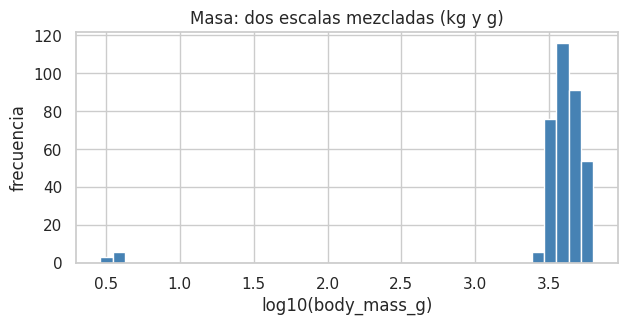

In [12]:
# Valores sospechosamente pequeños en la masa: ¿se capturaron en kg?
masa = sucio["body_mass_g"]
print(masa[masa < 100].sort_values().to_list())

# Histograma en escala log para ver los dos "grupos" de unidades
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(np.log10(masa.dropna()), bins=40, color="steelblue")
ax.set(xlabel="log10(body_mass_g)", ylabel="frecuencia", title="Masa: dos escalas mezcladas (kg y g)")
plt.show()

**Criterios típicos** (y siempre documentados):
- **Códigos centinela** (`-999`, `0`, `9999`, `"."`, `"NA"`): convertirlos a `NaN`.
- **Unidades:** si la regla es inequívoca (masa < 100 ⇒ estaba en kg), convertir; si no, marcar y consultar.
- **Fuera de rango plausible:** a `NaN` si es imposible; si solo es raro, **no** se toca aquí (eso es un *outlier*, sesión 3).

### 🟢 Ejercicio 3 · Normaliza las categorías
A partir de `sin_dup_llave` (si no hiciste el reto, usa `sin_dup.drop_duplicates(subset=["id_muestra"])`), crea `limpio` con `species`, `island` y `sex` normalizadas a: `Adelie/Chinstrap/Gentoo`, `Biscoe/Dream/Torgersen` y `Male/Female` (con `"."` convertido a `NaN`). Verifica con `value_counts(dropna=False)` que no queden variantes.

In [13]:
base_limpieza = sin_dup.drop_duplicates(subset=["id_muestra"])

mapa_sexo = {"male": "Male", "m": "Male", "female": "Female", "f": "Female"}   # "." no está -> NaN
limpio = base_limpieza.assign(
    species=lambda d: d["species"].str.strip().str.lower().map(mapa_especie),
    island=lambda d: d["island"].str.strip().str.title(),
    sex=lambda d: d["sex"].str.strip().str.lower().map(mapa_sexo),
)
for col in ["species", "island", "sex"]:
    print(limpio[col].value_counts(dropna=False), "\n")

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64 

island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64 

sex
Male      168
Female    165
NaN        11
Name: count, dtype: int64 



### 🟢 Ejercicio 4 · Rangos y unidades
En `limpio`:
1. Convierte a gramos las masas que están en kg (valores < 100).
2. Pon en `NaN` las aletas fuera de 150–250 mm y los picos fuera de 30–65 mm.
3. Reporta **cuántos valores** cambió cada regla. Compara `describe()` antes y después.

In [14]:
antes = limpio[["bill_length_mm", "flipper_length_mm", "body_mass_g"]].describe().T

en_kg = limpio["body_mass_g"] < 100
aleta_mala = limpio["flipper_length_mm"].notna() & ~limpio["flipper_length_mm"].between(150, 250)
pico_malo = limpio["bill_length_mm"].notna() & ~limpio["bill_length_mm"].between(30, 65)

limpio.loc[en_kg, "body_mass_g"] = limpio.loc[en_kg, "body_mass_g"] * 1000
limpio.loc[aleta_mala, "flipper_length_mm"] = np.nan
limpio.loc[pico_malo, "bill_length_mm"] = np.nan

print(f"masas convertidas de kg a g: {en_kg.sum()} | aletas a NaN: {aleta_mala.sum()} | picos a NaN: {pico_malo.sum()}")
despues = limpio[["bill_length_mm", "flipper_length_mm", "body_mass_g"]].describe().T
pd.concat({"antes": antes[["min", "mean", "max"]], "después": despues[["min", "mean", "max"]]}, axis=1).round(1)

masas convertidas de kg a g: 8 | aletas a NaN: 4 | picos a NaN: 2


antes                 después                
                     min    mean     max     min    mean     max
bill_length_mm      32.1    49.5   999.0    32.1    43.9    59.6
flipper_length_mm -999.0   198.8  2100.0   172.0   200.9   231.0
body_mass_g          2.9  4117.8  6300.0  2700.0  4202.4  6300.0

### 🔴 Reto 2 · Validador de reglas
Escribe `validar(df, reglas)` donde `reglas` es un diccionario `{columna: (mínimo, máximo)}` y devuelve un DataFrame con, por columna: `n_fuera_de_rango`, `pct_fuera_de_rango` y una lista de hasta 5 ejemplos. Aplícalo a `sucio` y a `limpio`. (Este tipo de función es oro en el proyecto integrador.)

In [15]:
def validar(df, reglas):
    filas = []
    for col, (lo, hi) in reglas.items():
        s = df[col]
        fuera = s.notna() & ~s.between(lo, hi)
        filas.append({"columna": col, "rango": f"[{lo}, {hi}]",
                      "n_fuera_de_rango": int(fuera.sum()),
                      "pct_fuera_de_rango": round(100 * fuera.mean(), 2),
                      "ejemplos": s[fuera].head(5).tolist()})
    return pd.DataFrame(filas).set_index("columna")

reglas = {"bill_length_mm": (30, 65), "bill_depth_mm": (12, 23),
          "flipper_length_mm": (150, 250), "body_mass_g": (2500, 6500)}
display(validar(sucio, reglas))
validar(limpio, reglas)

,rango,n_fuera_de_rango,pct_fuera_de_rango,ejemplos
columna,,,,
bill_length_mm,"[30, 65]",2,0.56,"[999.0, 999.0]"
bill_depth_mm,"[12, 23]",0,0.00,[]
flipper_length_mm,"[150, 250]",4,1.13,"[-999.0, 0.0, -999.0, 2100.0]"
body_mass_g,"[2500, 6500]",9,2.54,"[3.4, 3.775, 3.9, 4.1, 3.5]"


,rango,n_fuera_de_rango,pct_fuera_de_rango,ejemplos
columna,,,,
bill_length_mm,"[30, 65]",0,0.0,[]
bill_depth_mm,"[12, 23]",0,0.0,[]
flipper_length_mm,"[150, 250]",0,0.0,[]
body_mass_g,"[2500, 6500]",0,0.0,[]


---
## 3. Mecanismos de faltantes y cómo perfilarlos (15 min)

| Mecanismo | La probabilidad de faltar depende de… | Ejemplo | Consecuencia |
|---|---|---|---|
| **MCAR** (*Missing Completely At Random*) | nada: azar puro | Se cae una hoja del cuaderno de campo | Eliminar filas solo reduce *n*; no sesga |
| **MAR** (*Missing At Random*) | **otras variables observadas** | Falta la edad más en 3ra clase | Sesga si se ignora; se corrige condicionando (imputar por grupo) |
| **MNAR** (*Missing Not At Random*) | **el propio valor faltante** | Los de ingreso alto no reportan su ingreso | Sesga y los datos solos no pueden demostrarlo ni corregirlo |

⚠️ No existe una prueba que confirme MCAR o MAR con certeza: con los datos solo podemos **descartar** MCAR (si la falta depende de algo observado). MNAR se argumenta con conocimiento del dominio.

### Simulación: el mismo dataset con tres mecanismos
Tomamos las masas completas de `penguins`, les quitamos ~30% de valores con cada mecanismo y comparamos la media observada con la verdadera.

In [16]:
completos = pinguinos.dropna(subset=["body_mass_g"]).reset_index(drop=True)
masa_real = completos["body_mass_g"]

p_mcar = np.full(len(completos), 0.30)                                       # igual para todos
p_mar = np.where(completos["species"] == "Gentoo", 0.60, 0.15)               # depende de la especie (observada)
p_mnar = 0.6 / (1 + np.exp(-(masa_real - 4500) / 300))                       # depende de la propia masa

sim = completos[["species", "body_mass_g"]].copy()
for nombre, p in {"MCAR": p_mcar, "MAR": p_mar, "MNAR": p_mnar}.items():
    falta = rng.random(len(sim)) < p
    sim[f"masa_{nombre}"] = masa_real.mask(falta)

resumen_sim = pd.DataFrame({
    "% faltante": sim.filter(like="masa_").isna().mean() * 100,
    "media observada": sim.filter(like="masa_").mean(),
}).round(1)
resumen_sim["sesgo vs. real"] = (resumen_sim["media observada"] - masa_real.mean()).round(1)
print(f"Media real: {masa_real.mean():.1f} g")
resumen_sim

Media real: 4201.8 g


,% faltante,media observada,sesgo vs. real
masa_MCAR,33.0,4182.4,-19.4
masa_MAR,25.1,4033.0,-168.8
masa_MNAR,21.6,3977.5,-224.3


In [17]:
# Perfil por grupo: ¿la falta depende de la especie?
sim.filter(like="masa_").isna().groupby(sim["species"]).mean().round(2)

,masa_MCAR,masa_MAR,masa_MNAR
species,,,
Adelie,0.36,0.09,0.06
Chinstrap,0.22,0.10,0.04
Gentoo,0.36,0.53,0.50


- **MCAR:** la media casi no cambia y la proporción de faltantes es pareja entre especies.
- **MAR:** la falta es mucho mayor en Gentoo (¡lo vemos en el perfil!) y la media observada **subestima** porque perdemos a los más pesados. Como la causa (especie) está observada, podemos corregir condicionando en ella.
- **MNAR:** también subestima, pero el perfil por especie **no** revela la causa completa: depende del valor que no vemos.

### Herramientas para perfilar faltantes

                    n    %
species             0  0.0
island              0  0.0
bill_length_mm      2  0.6
bill_depth_mm       2  0.6
flipper_length_mm   2  0.6
body_mass_g         2  0.6
sex                11  3.2 

species  island  bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g  sex  
False    False   False           False          False              False        False    333
                                                                                True       9
                 True            True           True               True         True       2
Name: n_filas, dtype: int64 



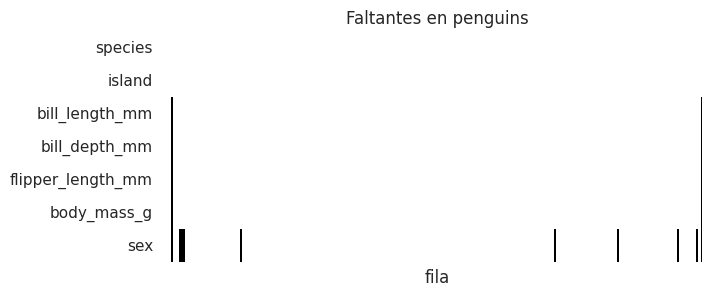

In [18]:
# 1) Conteo y porcentaje por columna
faltantes = pd.DataFrame({"n": pinguinos.isna().sum(), "%": (pinguinos.isna().mean() * 100).round(1)})
print(faltantes, "\n")

# 2) Patrones: qué combinaciones de columnas faltan juntas
patrones = pinguinos.isna().value_counts().rename("n_filas")
print(patrones, "\n")

# 3) Mapa visual de faltantes (cada línea clara es un NaN)
fig, ax = plt.subplots(figsize=(7, 3))
sns.heatmap(pinguinos.isna().T, cbar=False, cmap="Greys", ax=ax)
ax.set(xlabel="fila", title="Faltantes en penguins")
ax.set_xticks([])
plt.show()

### 🟢 Ejercicio 5 · ¿MCAR, MAR o MNAR?
Clasifica cada caso y justifica en una frase:
1. En una encuesta de salud, las personas con mayor consumo de alcohol tienden a no contestar la pregunta sobre consumo de alcohol.
2. Un lector de código de barras falla al azar en 2% de las lecturas.
3. En `tips`, imagina que el mesero olvidó anotar la propina más a menudo en las cenas de fin de semana (cuando hay más trabajo), y `day` y `time` sí están registrados.
4. En `penguins`, a 2 pingüinos les faltan **todas** las medidas.

**✅ Respuesta sugerida:**

1. **MNAR:** la falta depende del propio valor (consumo alto ⇒ no responde).
2. **MCAR:** la falla no depende de ninguna variable.
3. **MAR:** depende de `day` y `time`, que están observadas; se puede corregir condicionando en ellas.
4. Lo más probable es que sean individuos **no medidos** (se registró la presencia pero no se tomaron las medidas). Con solo 2 filas sin ninguna medida no hay forma de imputarlas con sentido: se **eliminan** y se documenta. Por sí solos no permiten distinguir el mecanismo, pero al ser 2 de 344 el impacto es mínimo.

---
## 4. Tratamiento de faltantes y su efecto (30 min)

| Estrategia | Cuándo | Costo |
|---|---|---|
| **Eliminar filas** (`dropna`) | Pocos faltantes y MCAR | Pierde *n*; sesga si no es MCAR |
| **Eliminar columna** | La columna casi no tiene datos o no es relevante | Pierde la variable |
| **Imputar media/mediana global** | Rápido, pocos faltantes | **Reduce la varianza**, crea un pico artificial, distorsiona relaciones |
| **Imputar por grupo** (`groupby().transform`) | MAR con la causa observada | Mejor, pero sigue subestimando la variabilidad dentro del grupo |
| **Indicador de faltante** | Siempre que se impute: conserva la información de *que faltaba* | Una columna más |
| (Avanzado) Imputación múltiple / modelos | Análisis inferencial serio | Más complejo; fuera del alcance de hoy |

Usemos el escenario **MAR** de la simulación, donde conocemos la verdad.

In [19]:
mar = sim[["species", "body_mass_g", "masa_MAR"]].copy()

mar["elim"] = mar["masa_MAR"]                                                  # dropna implícito al resumir
mar["imp_media"] = mar["masa_MAR"].fillna(mar["masa_MAR"].mean())
mar["imp_mediana"] = mar["masa_MAR"].fillna(mar["masa_MAR"].median())
mar["imp_grupo"] = mar["masa_MAR"].fillna(mar.groupby("species")["masa_MAR"].transform("median"))
mar["faltaba"] = mar["masa_MAR"].isna()                                        # indicador de faltante

estrategias = ["body_mass_g", "elim", "imp_media", "imp_mediana", "imp_grupo"]
tabla = mar[estrategias].agg(["count", "mean", "median", "std"]).T.round(1)
tabla.index = ["real (sin faltantes)", "eliminar", "media global", "mediana global", "mediana por especie"]
tabla

,count,mean,median,std
real (sin faltantes),342.0,4201.8,4050.0,802.0
eliminar,256.0,4033.0,3800.0,755.1
media global,342.0,4033.0,4033.0,653.0
mediana global,342.0,3974.4,3800.0,660.8
mediana por especie,342.0,4213.3,4000.0,786.8


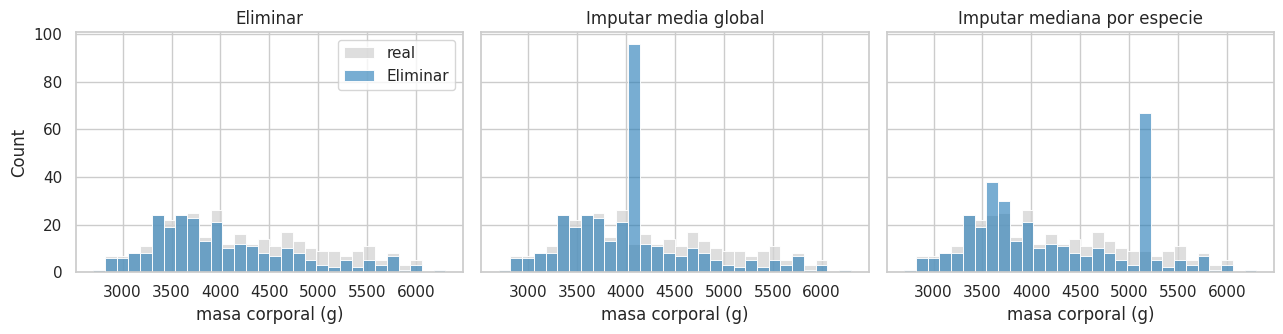

In [20]:
# Efecto visual en la distribución
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharex=True, sharey=True)
for ax, col, titulo in zip(axes, ["elim", "imp_media", "imp_grupo"],
                           ["Eliminar", "Imputar media global", "Imputar mediana por especie"]):
    sns.histplot(mar["body_mass_g"], bins=30, color="lightgray", label="real", ax=ax)
    sns.histplot(mar[col].dropna(), bins=30, color="tab:blue", alpha=0.6, label=titulo, ax=ax)
    ax.set(title=titulo, xlabel="masa corporal (g)")
axes[0].legend()
plt.tight_layout()
plt.show()

**Lecturas clave:**
- **Eliminar** con MAR sesga la media hacia abajo (perdimos Gentoo pesados).
- **Media/mediana global** crea un **pico artificial** y **encoge la desviación estándar**: subestima la variabilidad y hará que, más adelante, los intervalos de confianza sean falsamente estrechos.
- **Por grupo** recupera mejor la media y la forma, porque condiciona en la variable que explica la falta.
- Siempre conviene guardar el **indicador** (`faltaba`) para poder revisar después si los imputados se comportan distinto.

---
## 5. Ejercicio de la sesión (20 min + práctica)

### Parte A · `titanic`

### 🟢 Ejercicio 6 · Cuantifica los faltantes
Calcula el número y el porcentaje de faltantes de `age`, `deck` y `embark_town`. ¿Qué harías con cada una a primera vista?

In [21]:
cols = ["age", "deck", "embark_town"]
pd.DataFrame({
    "n_faltantes": titanic[cols].isna().sum(),
    "pct": (titanic[cols].isna().mean() * 100).round(1),
})

,n_faltantes,pct
age,177,19.9
deck,688,77.2
embark_town,2,0.2


**✅ Respuesta sugerida:**

- `age` (~19.9%): demasiados para eliminar sin perder información; candidata a imputar **por grupo** con indicador.
- `deck` (~77%): la mayoría falta; imputar inventaría datos. Mejor tratarla como categoría `"Desconocido"` o no usarla.
- `embark_town` (2 filas): tan pocos que eliminar o imputar con la moda no cambia nada; se documenta.

### 🟢 Ejercicio 7 · ¿La falta de `age` depende de `class`?
Calcula la proporción de `age` faltante por `class` (y, si quieres, por `sex` y por `embark_town`). Con base en eso, ¿es plausible que sea MCAR? Haz una gráfica de barras de la proporción por clase.

class
First     0.139
Second    0.060
Third     0.277
Name: age, dtype: float64 

sex
female    0.169
male      0.215
Name: age, dtype: float64 

embark_town
Cherbourg      0.226
Queenstown     0.636
Southampton    0.140
Name: age, dtype: float64


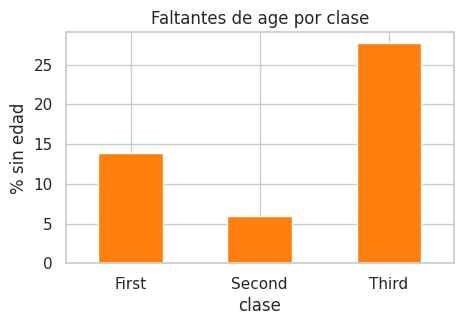

In [22]:
falta_age = titanic["age"].isna()
por_clase = falta_age.groupby(titanic["class"]).mean().reindex(["First", "Second", "Third"])
print(por_clase.round(3), "\n")
print(falta_age.groupby(titanic["sex"]).mean().round(3), "\n")
print(falta_age.groupby(titanic["embark_town"]).mean().round(3))

ax = por_clase.mul(100).plot.bar(color="tab:orange", rot=0, figsize=(5, 3))
ax.set(ylabel="% sin edad", xlabel="clase", title="Faltantes de age por clase")
plt.show()

**✅ Respuesta sugerida:**

La falta de `age` es mucho mayor en **tercera clase** (~28%) que en primera (~14%) y segunda (~6%), y también varía por puerto (muy alta en Queenstown). **No parece MCAR**: depende de variables observadas, lo que es compatible con **MAR** (aunque no podemos descartar MNAR). Por eso conviene imputar condicionando en `class` (y `sex`).

### 🟢 Ejercicio 8 · Mediana global vs. mediana por `class` y `sex`
1. Crea `age_med_global` (imputando con la mediana global) y `age_med_grupo` (con la mediana por `class` y `sex`, usando `groupby(...).transform("median")`), además de un indicador `age_faltaba`.
2. Compara media, mediana y desviación estándar de `age` original y de las dos versiones imputadas.
3. Grafica las tres distribuciones (histograma o KDE). ¿Qué estrategia distorsiona menos? ¿Qué le pasa a la desviación estándar?

Medianas por clase y sexo usadas para imputar:
sex     female  male
class               
First     35.0  40.0
Second    28.0  30.0
Third     21.5  25.0 

                count   mean  median    std
age             714.0  29.70    28.0  14.53
age_med_global  891.0  29.36    28.0  13.02
age_med_grupo   891.0  29.11    26.0  13.30


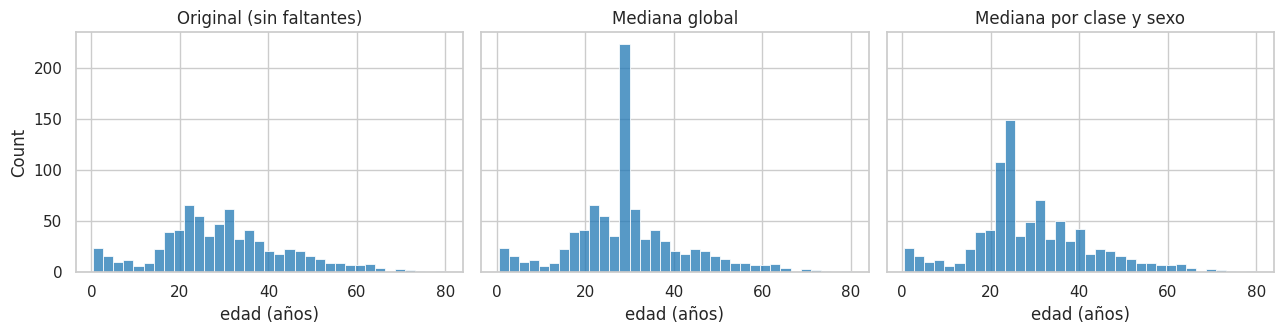

In [23]:
tt = titanic.copy()
tt["age_faltaba"] = tt["age"].isna()
tt["age_med_global"] = tt["age"].fillna(tt["age"].median())
tt["age_med_grupo"] = tt["age"].fillna(tt.groupby(["class", "sex"])["age"].transform("median"))

print("Medianas por clase y sexo usadas para imputar:")
print(tt.groupby(["class", "sex"])["age"].median().unstack(), "\n")

comp = tt[["age", "age_med_global", "age_med_grupo"]].agg(["count", "mean", "median", "std"]).T.round(2)
print(comp)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharex=True, sharey=True)
for ax, col, titulo in zip(axes, ["age", "age_med_global", "age_med_grupo"],
                           ["Original (sin faltantes)", "Mediana global", "Mediana por clase y sexo"]):
    sns.histplot(tt[col].dropna(), bins=35, ax=ax, color="tab:blue")
    ax.set(title=titulo, xlabel="edad (años)")
plt.tight_layout()
plt.show()

**✅ Respuesta sugerida:**

- La **mediana global** (28 años) mete 177 valores idénticos: aparece una barra gigante en 28 y la desviación estándar baja de ~14.5 a ~13.0.
- La **mediana por clase y sexo** reparte los imputados entre varios valores (de ~21.5 a 40 años), conserva mejor la forma y la relación edad–clase (primera clase es mayor), y reduce menos la desviación estándar.
- Ambas **subestiman la variabilidad** (todos los imputados de un grupo valen lo mismo). Por eso guardamos `age_faltaba` y, en inferencia, lo tendremos presente.

### 🔴 Reto 3 · `deck` y `embark_town`, y un adelanto de inferencia
1. Propón y aplica un tratamiento para `deck` (77% faltante) y para `embark_town` (2 filas). Justifica.
2. **Adelanto de la sesión 6:** con `pd.crosstab` y `scipy.stats.chi2_contingency`, prueba si la falta de `age` es independiente de `class`. Interpreta el valor p con cuidado.
3. ¿La tasa de supervivencia es distinta entre quienes tienen y no tienen `age` registrada? ¿Qué implicaría eso para un análisis que simplemente borra esas filas?

In [24]:
from scipy import stats

tt2 = titanic.copy()
# 1. deck: categoría explícita "Desconocido" (no inventamos cubiertas); embark_town: moda (solo 2 filas)
tt2["deck"] = tt2["deck"].fillna("Desconocido")
moda = tt2["embark_town"].mode()[0]
tt2["embark_town"] = tt2["embark_town"].fillna(moda)
print(tt2["deck"].value_counts(), "\n")
print("embark_town imputado con:", moda, "\n")

# 2. Chi cuadrada de independencia: faltante de age vs. class
tabla = pd.crosstab(titanic["class"], titanic["age"].isna().rename("age_faltante"))
chi2, p, gl, esperadas = stats.chi2_contingency(tabla)
print(tabla, f"\nchi2 = {chi2:.1f}, gl = {gl}, p = {p:.2g}\n")
# p muy pequeño: si la falta fuera independiente de la clase, una asociación así sería muy improbable.
# Esto descarta MCAR respecto a class, pero NO prueba que sea MAR.

# 3. Supervivencia según si hay edad registrada
print(titanic.groupby(titanic["age"].isna().rename("age_faltante"))["survived"].mean().round(3))
# Sobreviven menos los que no tienen edad (~29% vs ~41%): borrar esas filas sobreestimaría la supervivencia.

deck
Desconocido    688
C               59
B               47
D               33
E               32
A               15
F               13
G                4
Name: count, dtype: int64 

embark_town imputado con: Southampton 

age_faltante  False  True 
class                     
First           186     30
Second          173     11
Third           355    136 
chi2 = 46.1, gl = 2, p = 9.9e-11

age_faltante
False    0.406
True     0.294
Name: survived, dtype: float64


### Parte B · Auditoría de `penguins` y dataset limpio para las siguientes sesiones

### 🟢 Ejercicio 9 · Aplica la misma auditoría a `penguins` (el original, no `sucio`)
1. Recorre la lista de verificación: tipos, duplicados, categorías (`value_counts`), rangos y faltantes por columna y por patrón.
2. Identifica las **filas sin medidas** y las filas con **`sex` faltante**. ¿La falta de `sex` se concentra en alguna especie o isla?
3. Decide y justifica: ¿qué haces con las filas sin medidas? ¿imputas `sex`?

In [25]:
medidas = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

# 1. Lista de verificación
print("duplicados exactos:", pinguinos.duplicated().sum())
for col in ["species", "island", "sex"]:
    print(pinguinos[col].value_counts(dropna=False).to_dict())
print(pinguinos[medidas].describe().T[["min", "max"]], "\n")   # todo en rangos plausibles

# 2. Filas sin medidas y sex faltante
sin_medidas = pinguinos[medidas].isna().all(axis=1)
print("filas sin ninguna medida:", sin_medidas.sum())
display(pinguinos[sin_medidas])
sexo_falta = pinguinos["sex"].isna()
print("sex faltante:", sexo_falta.sum(), "| de ellas sin medidas:", (sexo_falta & sin_medidas).sum())
print(pinguinos[sexo_falta].groupby(["species", "island"]).size())

duplicados exactos: 0
{'Adelie': 152, 'Gentoo': 124, 'Chinstrap': 68}
{'Biscoe': 168, 'Dream': 124, 'Torgersen': 52}
{'MALE': 168, 'FEMALE': 165, nan: 11}
                      min     max
bill_length_mm       32.1    59.6
bill_depth_mm        13.1    21.5
flipper_length_mm   172.0   231.0
body_mass_g        2700.0  6300.0 

filas sin ninguna medida: 2


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN


sex faltante: 11 | de ellas sin medidas: 2
species  island   
Adelie   Dream        1
         Torgersen    5
Gentoo   Biscoe       5
dtype: int64


**✅ Respuesta sugerida:**

- **Duplicados:** no hay. **Categorías:** consistentes, pero `sex` viene en mayúsculas (`MALE`/`FEMALE`); lo pasamos a `Male`/`Female` para homologar con *Seaborn* y con `sucio`. **Rangos:** plausibles.
- **2 filas sin ninguna medida** (y sin `sex`): no aportan nada al análisis de medidas → **se eliminan** y se documenta (2 de 344, 0.6%).
- **`sex` faltante en 11 filas** (9 tras eliminar las 2 anteriores), todas en Adelie (Torgersen y Dream) y Gentoo; ninguna en Chinstrap. **No se imputa**: inventar el sexo sesgaría las comparaciones por sexo de las sesiones 5 y 6. Se deja como `NaN` y cada análisis por sexo excluye esas filas explícitamente.

### Dataset limpio de referencia (`data/penguins_limpio.csv`)
Para que **todos empecemos la sesión 3 con los mismos datos**, la siguiente celda aplica las decisiones acordadas y guarda el resultado. Compárala con lo que hiciste en el ejercicio 9.

Decisiones: (1) `sex` → `Male`/`Female`; (2) eliminar las filas sin ninguna medida; (3) **no** imputar `sex`; (4) tipos: `category` para las categóricas e `Int64` para aleta y masa.

In [26]:
medidas = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

penguins_limpio = (
    pinguinos
    .assign(sex=lambda d: d["sex"].str.title())                 # MALE -> Male
    .dropna(subset=medidas, how="all")                           # quita filas sin ninguna medida
    .astype({"species": "category", "island": "category", "sex": "category",
             "flipper_length_mm": "Int64", "body_mass_g": "Int64"})
    .reset_index(drop=True)
)

print("filas:", len(pinguinos), "->", len(penguins_limpio))
print("faltantes restantes:\n", penguins_limpio.isna().sum())

penguins_limpio.to_csv(os.path.join(DATA, "penguins_limpio.csv"), index=False)
print("\nGuardado en", os.path.join(DATA, "penguins_limpio.csv"))

filas: 344 -> 342
faltantes restantes:
 species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  9
dtype: int64

Guardado en ../data/penguins_limpio.csv


### 🔴 Reto 4 · Impacto de las decisiones
Compara la masa media por especie y sexo en `pinguinos` (original) y en `penguins_limpio`. ¿Cambió algo? ¿Por qué era de esperarse ese resultado? Después, calcula cuánto cambiaría la masa media por especie si hubieras imputado `sex` con la **moda** de cada especie: ¿qué sexo "gana" artificialmente?

In [27]:
orig = (pinguinos.assign(sex=pinguinos["sex"].str.title())
        .groupby(["species", "sex"])["body_mass_g"].mean())
limp = penguins_limpio.groupby(["species", "sex"], observed=True)["body_mass_g"].mean()
print(pd.concat({"original": orig, "limpio": limp}, axis=1).round(1), "\n")
# No cambia: las filas eliminadas no tenían medidas, así que no entraban en ningún promedio.

# Imputación de sex con la moda por especie
moda_sexo = penguins_limpio.groupby("species", observed=True)["sex"].agg(lambda s: s.mode()[0])
imputado = penguins_limpio.assign(
    sex=lambda d: d["sex"].astype(object).fillna(d["species"].map(moda_sexo).astype(object))
)
print("Moda por especie:", moda_sexo.to_dict())
comparacion = pd.concat({
    "sin imputar": penguins_limpio.groupby(["species", "sex"], observed=True)["body_mass_g"].mean(),
    "sex imputado con la moda": imputado.groupby(["species", "sex"], observed=True)["body_mass_g"].mean(),
}, axis=1).round(1)
print(comparacion)
print("\nConteos tras imputar:\n", imputado.groupby(["species", "sex"], observed=True).size())
# Todos los faltantes de una especie se asignan al mismo sexo: se infla ese grupo
# y se mezclan en él individuos que pueden ser del otro sexo, sesgando las comparaciones.

                  original  limpio
species   sex                     
Adelie    Female    3368.8  3368.8
          Male      4043.5  4043.5
Chinstrap Female    3527.2  3527.2
          Male      3939.0  3939.0
Gentoo    Female    4679.7  4679.7
          Male      5484.8  5484.8 

Moda por especie: {'Adelie': 'Female', 'Chinstrap': 'Female', 'Gentoo': 'Male'}
                  sin imputar  sex imputado con la moda
species   sex                                          
Adelie    Female       3368.8                    3379.8
          Male         4043.5                    4043.5
Chinstrap Female       3527.2                    3527.2
          Male         3939.0                    3939.0
Gentoo    Female       4679.7                    4679.7
          Male         5484.8                    5429.6

Conteos tras imputar:
 species    sex   
Adelie     Female    78
           Male      73
Chinstrap  Female    34
           Male      34
Gentoo     Female    58
           Male      65
dtyp

---
## ✅ Cierre

**Hoy vimos:**
- La **lista de verificación de calidad** que usaremos en todo el curso.
- Duplicados exactos vs. por llave, y por qué un duplicado sin llave no siempre es un error (`titanic`).
- Inconsistencias: texto, categorías, códigos centinela, rangos imposibles y unidades.
- Mecanismos **MCAR / MAR / MNAR** y cómo perfilarlos.
- Tratamientos y su costo: eliminar sesga si no es MCAR; imputar con un valor único **encoge la varianza**; imputar por grupo es mejor si la causa está observada; guarda siempre el indicador.

**Práctica (sin calificación, en Classroom):** termina los ejercicios 🟢 y verifica que exista `data/penguins_limpio.csv`.

**Próxima sesión (mié 21 oct):** estadística descriptiva, forma de la distribución y outliers (`03_descriptiva_distribuciones.ipynb`), sobre `penguins_limpio`.

<p style="text-align: center"><a rel="license" href="http://creativecommons.org/licenses/by/4.0/"><img alt="Licencia Creative Commons" style="border-width:0" src="https://i.creativecommons.org/l/by/4.0/80x15.png" /></a><br />Esta obra está bajo una <a rel="license" href="http://creativecommons.org/licenses/by/4.0/">Licencia Creative Commons Atribución 4.0 Internacional</a>.</p>
<p style="text-align: center">&copy; José Luis Chiquete Valdivieso. 2017-2026.</p>